# DATA_EXPLORATION

Descriptive statistics, figures and correlation screening. Reads the output of DATA_PROCESSING. No datasets are created and no models are trained here.

## 1. Imports and configuration

In [1]:
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures

In [2]:
MANIFEST_PATH = Path("data/processed/manifest.json")
IMAGES_PATH = Path("images/exploration")
RESULTS_DIR = Path("results/exploration")

PLOT_RESAMPLE = "30s" # display resampling of the 10 Hz series (like in the original figures)
FEATURE_PLOT_SAMPLING = "30SEC" # dataset used for weather / target plots
PAIRPLOT_TARGET = "RSTDEV_FWD_300_SAVGOL"
POLY_TOP_N = 5

mpl.rc("axes", labelsize=14)
mpl.rc("xtick", labelsize=12)
mpl.rc("ytick", labelsize=12)
IMAGES_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

manifest = json.loads(MANIFEST_PATH.read_text())
TZ = manifest["display_timezone"]
FEATURES = manifest["feature_columns"]
TARGET_META = {t["name"]: t for t in manifest["targets"]}
PRIMARY_TARGETS = [t["name"] for t in manifest["targets"] if t["primary"]]

## 2. Helper functions

In [3]:
def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    # Figure saving helper borrowed from Dr. Borghetti's class
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)


def local_time(ms):
    t = pd.to_datetime(ms, unit="ms", utc=True)
    return t.dt.tz_convert(TZ) if isinstance(t, pd.Series) else t.tz_convert(TZ)


def shade_nights(ax):
    for start, end in manifest["night_periods_utc_s"]:
        ax.axvspan(local_time(start * 1000), local_time(end * 1000), color="gray", alpha=0.3, zorder=0)


def format_date_axis(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(tz=TZ))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=TZ))


def non_test_rows(df, sampling):
    """Rows before the test period (row-index split from the manifest)."""
    s = manifest["splits"][sampling]
    return df.iloc[: s["n_train"] + s["n_validation"]]

## 3. Load processed data

In [4]:
fid = pd.read_csv(manifest["files"]["fidelity_10hz"])
fid.index = local_time(fid["current_time"])
datasets = {s: pd.read_csv(p) for s, p in manifest["files"]["datasets"].items()}
for df in datasets.values():
    df["dt"] = local_time(df["current_time"])
plot_df = datasets[FEATURE_PLOT_SAMPLING]
print(f"10 Hz rows: {len(fid):,};", {s: len(d) for s, d in datasets.items()})

10 Hz rows: 2,472,354; {'30SEC': 8237, '1MIN': 4119, '2MIN': 2060}


## 4. Descriptive statistics (Table 1) and degree of polarization

In [5]:
table1 = fid[["Fidelity", "S0", "S1", "S2", "S3"]].describe().loc[["mean", "std", "min", "25%", "50%", "75%", "max"]]
table1.to_csv(RESULTS_DIR / "table1_descriptive_statistics.csv")
table1.map(lambda v: f"{v:.2e}")

,Fidelity,S0,S1,S2,S3
mean,5.23e-01,5.82e-04,5.80e-02,-6.83e-02,-2.47e-02
std,2.71e-01,1.44e-04,5.66e-01,5.61e-01,5.97e-01
min,5.19e-06,0.00e+00,-1.00e+00,-1.00e+00,-1.00e+00
25%,2.98e-01,4.40e-04,-4.36e-01,-5.49e-01,-5.44e-01
50%,5.34e-01,5.70e-04,1.28e-01,-8.49e-02,-6.59e-02
75%,7.47e-01,7.10e-04,5.28e-01,4.11e-01,5.24e-01
max,1.00e+00,8.70e-04,1.00e+00,1.00e+00,1.00e+00


In [6]:
pd.read_csv(manifest["files"]["dop_statistics"])

,quantity,n,mean,std,min,q01,median,q99,max,frac |DOP-1| > 0.05
0,stokes_norm,2472354,1.000089,0.000158,0.994379,0.999940,1.000085,1.000251,1.023941,0.000000
1,DOP_calc,2472354,1.000089,0.000158,0.994379,0.999940,1.000085,1.000251,1.023941,0.000000
2,DOP_percent / 100,2472354,1.005547,0.024304,0.000000,0.968597,0.999390,1.054962,1.999969,0.020722


Saving figure stokes_norm_distribution


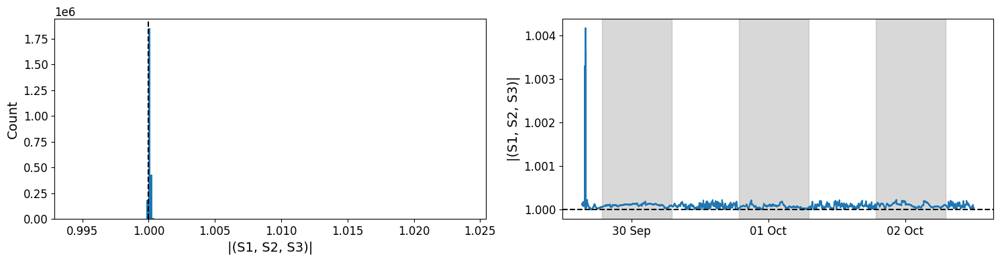

In [7]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 4))
ax0.hist(fid["stokes_norm"].dropna(), bins=200)
ax0.axvline(1.0, color="black", linestyle="--")
ax0.set_xlabel("|(S1, S2, S3)|")
ax0.set_ylabel("Count")
ax1.plot(fid["stokes_norm"].resample(PLOT_RESAMPLE).mean())
ax1.axhline(1.0, color="black", linestyle="--")
shade_nights(ax1)
format_date_axis(ax1)
ax1.set_ylabel("|(S1, S2, S3)|")
save_fig("stokes_norm_distribution")
plt.show()

## 5. Temporal plots

### 5.1 Stokes components (Fig. 5)

Saving figure stokes_S1_S2_S3_vs_time_EST


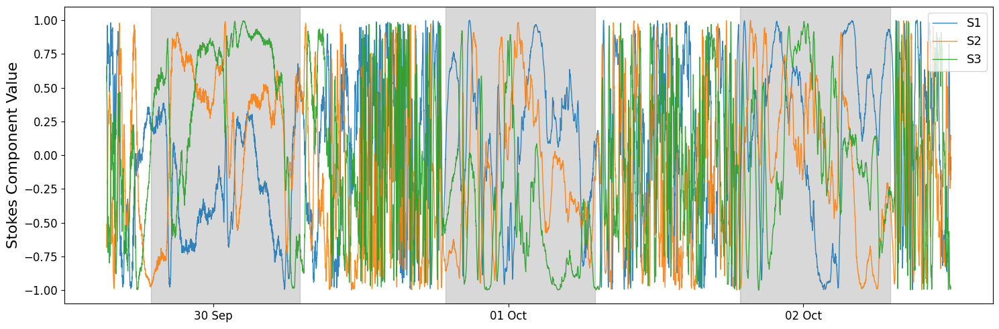

In [8]:
stokes = fid[["S1", "S2", "S3"]].resample(PLOT_RESAMPLE).mean()
fig, ax1 = plt.subplots(figsize=(15, 5))
for c in ["S1", "S2", "S3"]:
    ax1.plot(stokes.index, stokes[c], label=c, linewidth=1.0, alpha=0.9, zorder=2)
shade_nights(ax1)
format_date_axis(ax1)
ax1.set_ylabel("Stokes Component Value", fontsize=16)
legend = ax1.legend(loc="upper right", frameon=True, fontsize=13)
legend.get_frame().set_facecolor("white")
save_fig("stokes_S1_S2_S3_vs_time_EST")
plt.show()

### Fidelity (fixed per revioewer item)

Saving figure fidelity_vs_time_with_splits


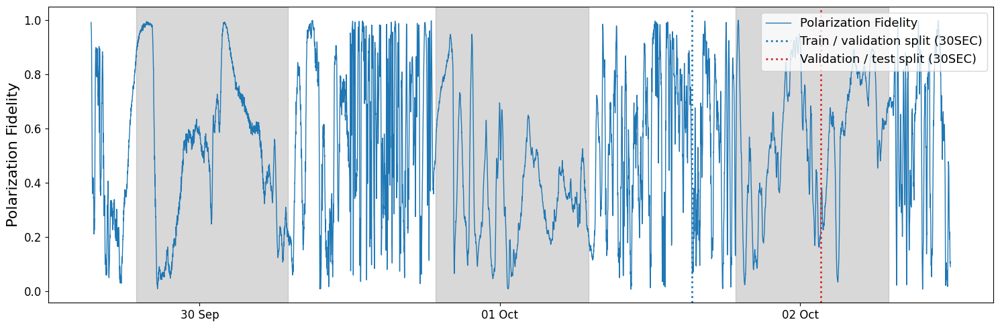

In [10]:
fid_rs = fid["Fidelity"].resample(PLOT_RESAMPLE).mean()
split = manifest["splits"][FEATURE_PLOT_SAMPLING]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(fid_rs.index, fid_rs, linewidth=1.0, label="Polarization Fidelity")
ax1.axvline(local_time(split["validation_start_ms"]), color="tab:blue", linestyle=":", linewidth=2, label=f"Train / validation split ({FEATURE_PLOT_SAMPLING})")
ax1.axvline(local_time(split["test_start_ms"]), color="tab:red", linestyle=":", linewidth=2, label=f"Validation / test split ({FEATURE_PLOT_SAMPLING})")
shade_nights(ax1)
format_date_axis(ax1)
ax1.set_ylabel("Polarization Fidelity", fontsize=16)
legend = ax1.legend(loc="upper right", frameon=True, fontsize=13)
legend.get_frame().set_facecolor("white")
save_fig("fidelity_vs_time_with_splits")
plt.show()

### 5.2 Wind speed and polarization fidelity (Fig 1)

Saving figure wind_speed_vs_time_with_fidelity


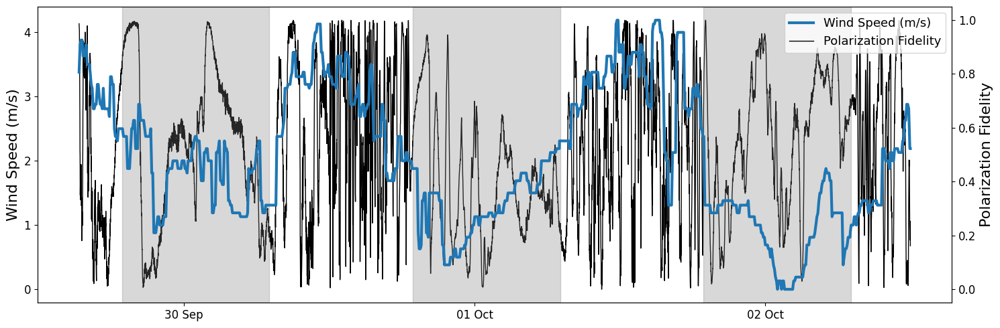

In [9]:
fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(plot_df["dt"], plot_df["wind_speed_x"], label="Wind Speed (m/s)", linewidth=3.0, zorder=1)
ax2 = ax1.twinx()
ax2.plot(plot_df["dt"], plot_df["Fidelity"], label="Polarization Fidelity", color="black", linewidth=1.0, zorder=0)
shade_nights(ax1)
format_date_axis(ax1)
ax1.set_ylabel("Wind Speed (m/s)", fontsize=16)
ax2.set_ylabel("Polarization Fidelity", fontsize=16)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
legend = ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", frameon=True, fontsize=13)
legend.get_frame().set_facecolor("white")
legend.set_zorder(10)
ax2.set_zorder(0)
ax1.set_zorder(1)
ax1.patch.set_visible(False)
save_fig("wind_speed_vs_time_with_fidelity")
plt.show()

### 5.3 First and second derivatives of fidelity before resampling (Fig 6)

Saving figure dF_and_d2F_same_axis_EST


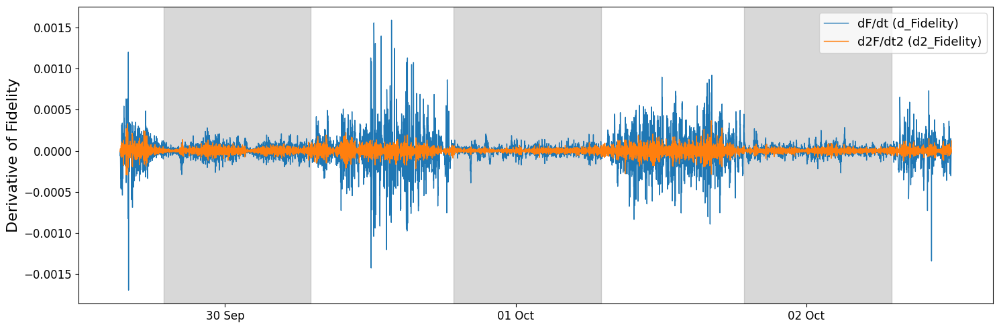

In [10]:
d1 = fid["Fidelity"].diff()
d2 = d1.diff()
fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(d1.resample(PLOT_RESAMPLE).mean(), label="dF/dt (d_Fidelity)", linewidth=1.0, zorder=2)
ax1.plot(d2.resample(PLOT_RESAMPLE).mean(), label="d2F/dt2 (d2_Fidelity)", linewidth=1.0, zorder=3)
shade_nights(ax1)
format_date_axis(ax1)
ax1.set_ylabel("Derivative of Fidelity", fontsize=16)
ax1.legend(loc="upper right", frameon=True, fontsize=13)
save_fig("dF_and_d2F_same_axis_EST")
plt.show()

## 6. Environmental features

### 6.1 Node X / Node Y weather variables

Saving figure cloud_cover_x_y_vs_time


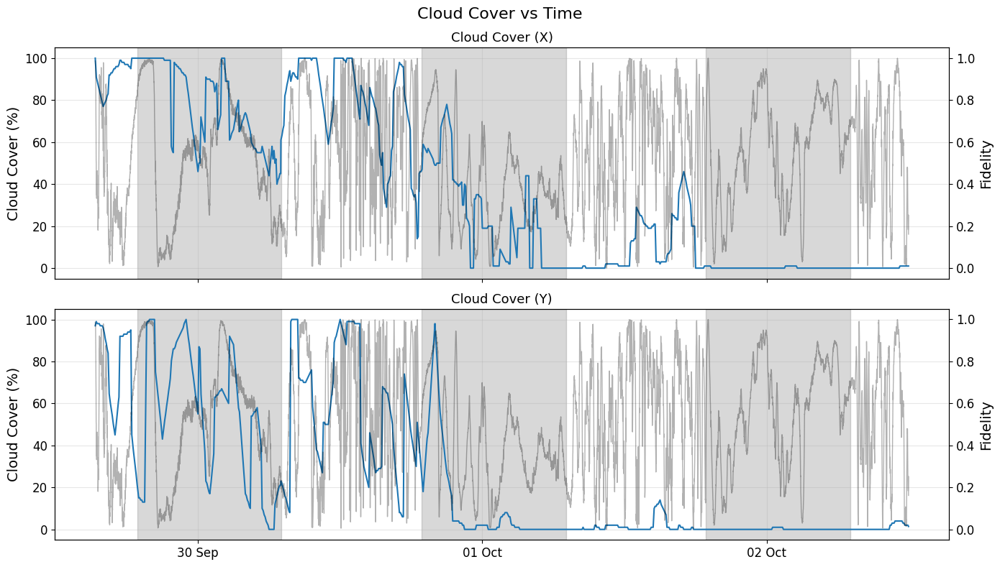

Saving figure humidity_x_y_vs_time


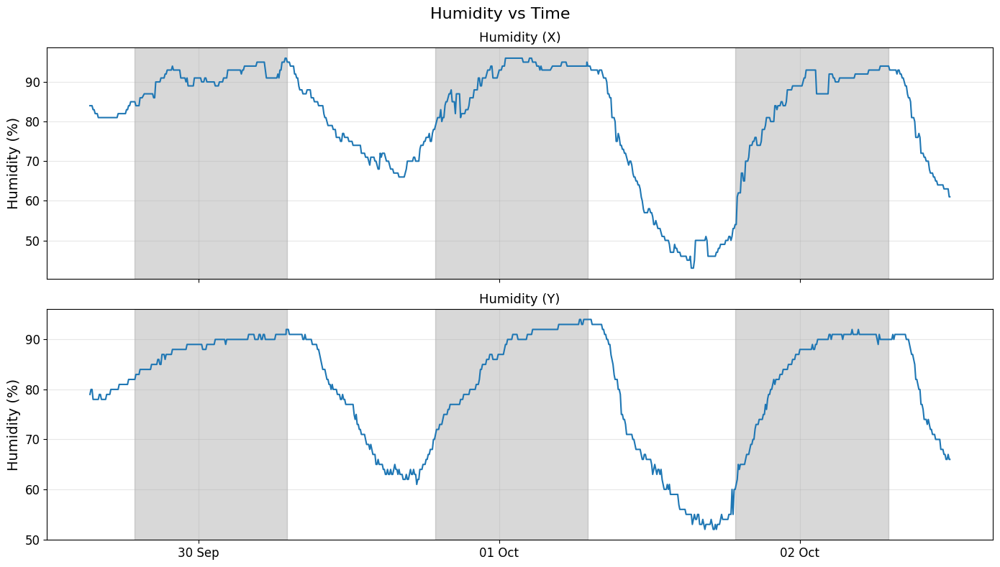

Saving figure temperature_x_y_vs_time


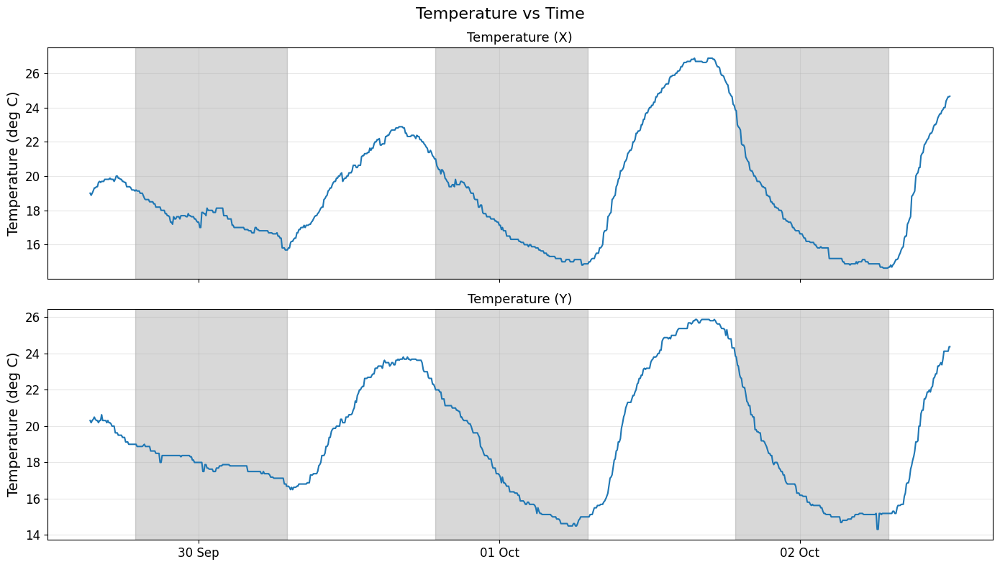

Saving figure pressure_x_y_vs_time


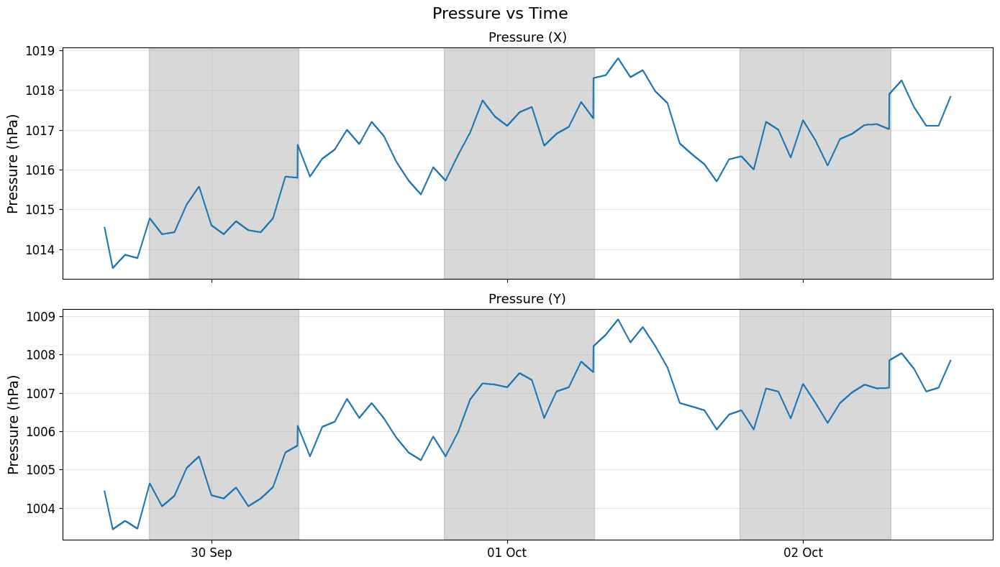

Saving figure vis_x_y_vs_time


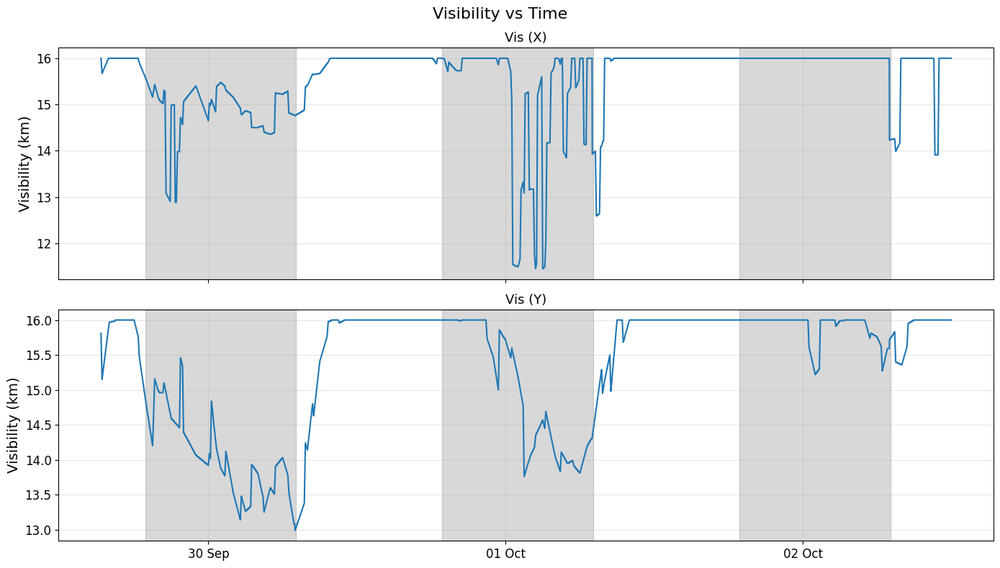

Saving figure wind_gust_x_y_vs_time


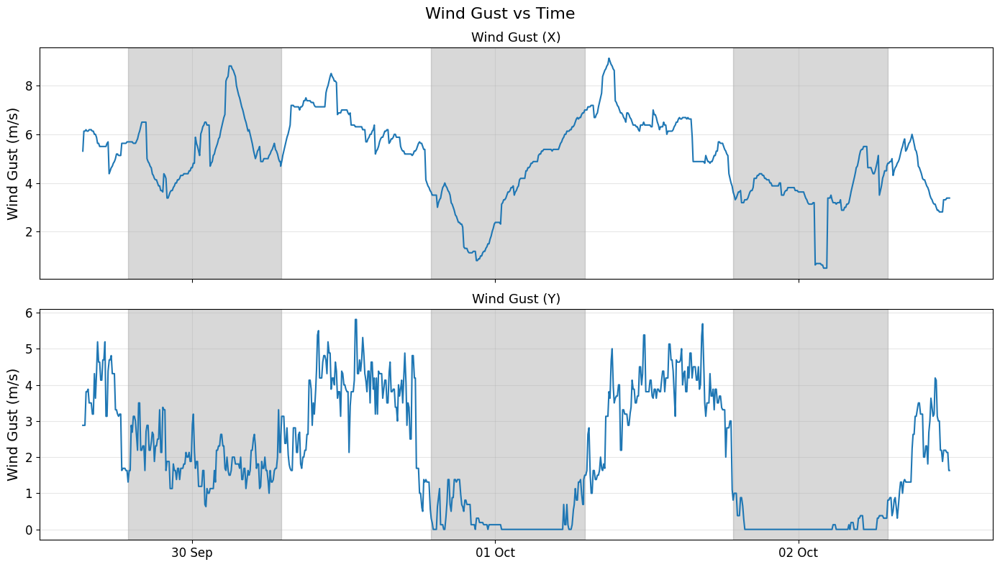

Saving figure wind_speed_x_y_vs_time


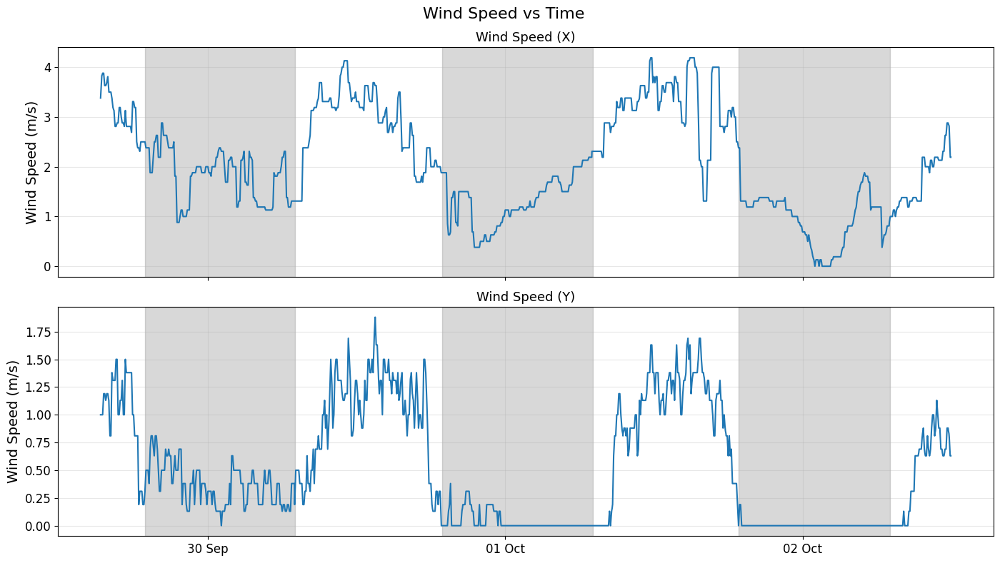

Saving figure wind_dir_x_y_vs_time


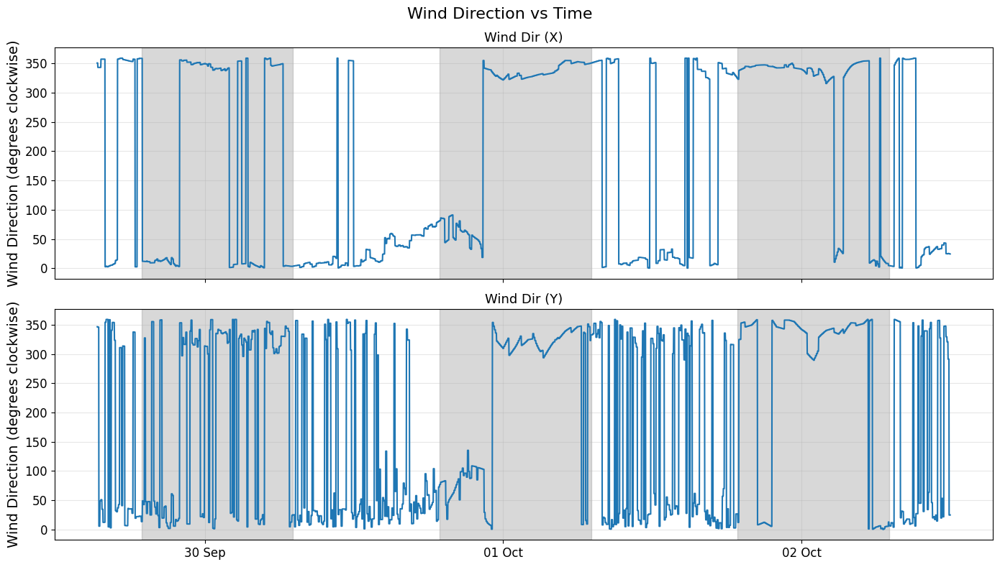

Saving figure wind_dir_sin_x_y_vs_time


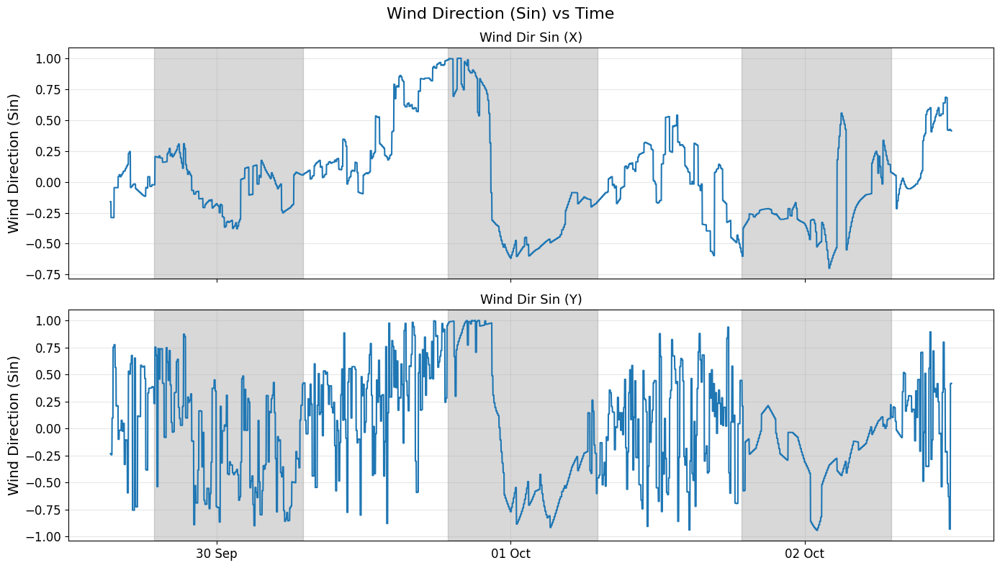

Saving figure wind_dir_cos_x_y_vs_time


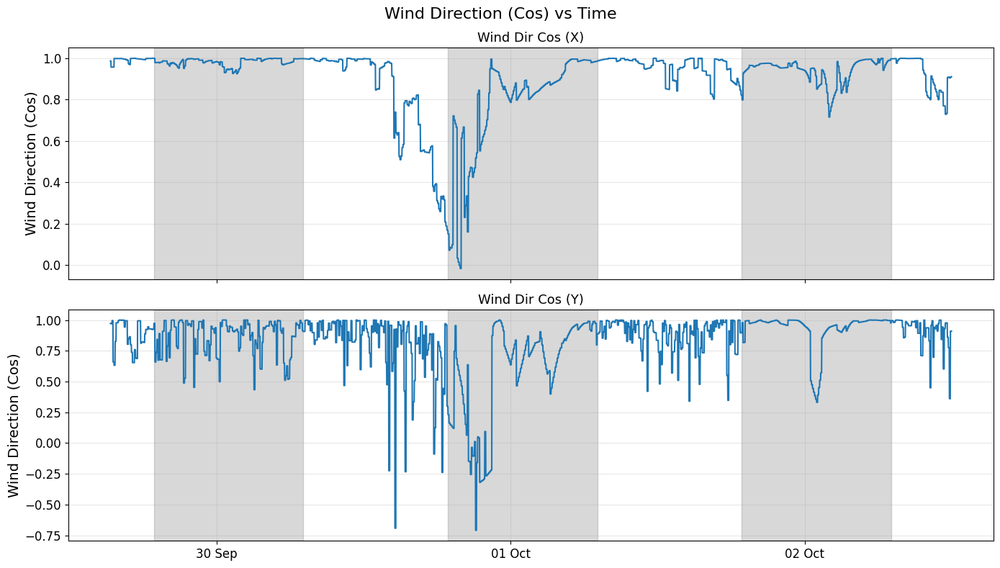

Saving figure wind_u_x_y_vs_time


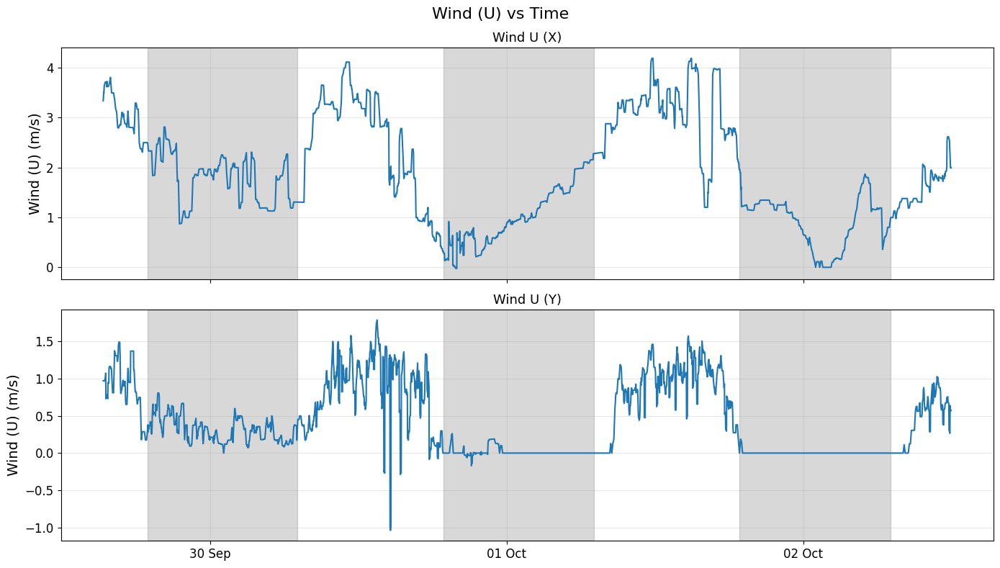

Saving figure wind_v_x_y_vs_time


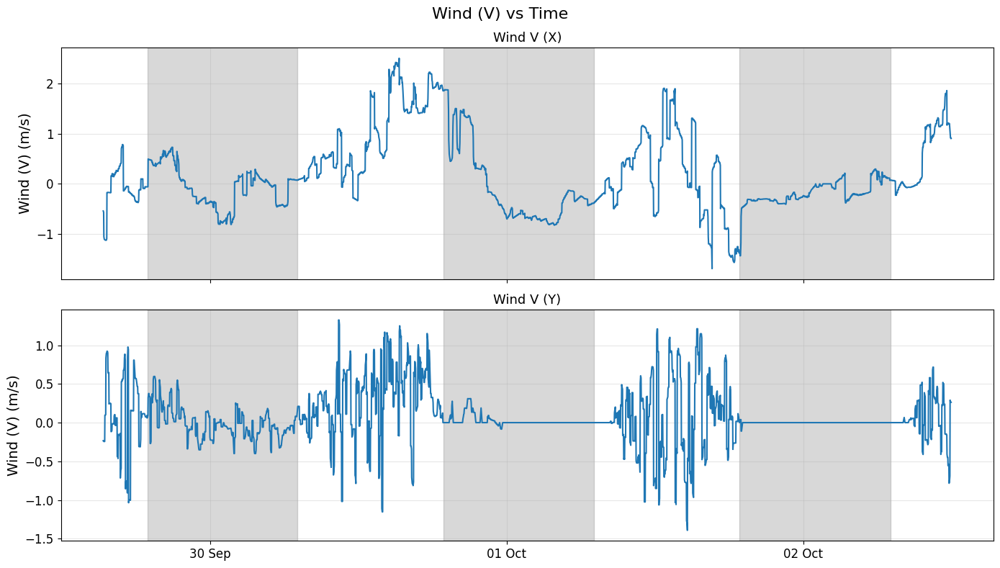

In [11]:
def plot_feature_xy(df, feature, y_label, unit=None, overlay_fidelity=False):
    fig, axes = plt.subplots(nrows=2, ncols=1, sharex=True, figsize=(14, 8))
    for ax, node in zip(axes, ["x", "y"]):
        ax.plot(df["dt"], df[f"{feature}_{node}"])
        ax.set_title(f"{feature.replace('_', ' ').title()} ({node.upper()})", fontsize=13)
        ax.set_ylabel(f"{y_label} ({unit})" if unit else y_label)
        if overlay_fidelity:
            twin = ax.twinx()
            twin.plot(df["dt"], df["Fidelity"], color="black", linewidth=1.0, alpha=0.3)
            twin.set_ylabel("Fidelity")
        shade_nights(ax)
        ax.grid(True, alpha=0.3)
    format_date_axis(axes[-1])
    fig.suptitle(f"{y_label} vs Time", fontsize=16, y=0.98)
    save_fig(f"{feature}_x_y_vs_time")
    plt.show()


WEATHER_PLOTS = [
    ("cloud_cover", "Cloud Cover", "%"), ("humidity", "Humidity", "%"), ("temperature", "Temperature", "deg C"),
    ("pressure", "Pressure", "hPa"), ("vis", "Visibility", "km"), ("wind_gust", "Wind Gust", "m/s"),
    ("wind_speed", "Wind Speed", "m/s"), ("wind_dir", "Wind Direction", "degrees clockwise"),
    ("wind_dir_sin", "Wind Direction (Sin)", None), ("wind_dir_cos", "Wind Direction (Cos)", None),
    ("wind_u", "Wind (U)", "m/s"), ("wind_v", "Wind (V)", "m/s"),
]
for feature, label, unit in WEATHER_PLOTS:
    plot_feature_xy(plot_df, feature, label, unit, overlay_fidelity=(feature == "cloud_cover"))

### 6.2 Time-of-day components

Saving figure time_of_day_components


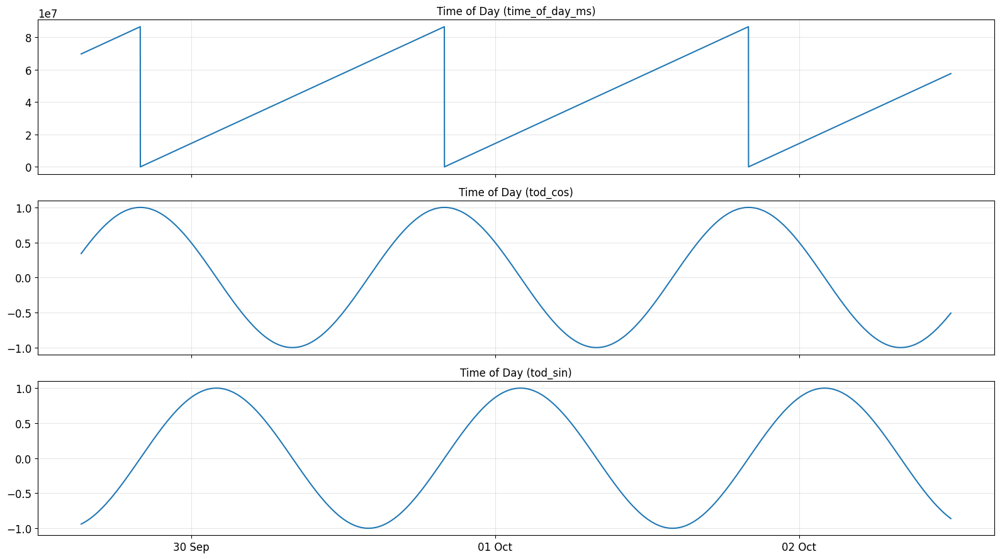

In [12]:
fig, axes = plt.subplots(nrows=3, ncols=1, sharex=True, figsize=(16, 9))
for ax, col in zip(axes, ["time_of_day_ms", "tod_cos", "tod_sin"]):
    ax.plot(plot_df["dt"], plot_df[col])
    ax.set_title(f"Time of Day ({col})")
    ax.grid(True, alpha=0.3)
format_date_axis(axes[-1])
save_fig("time_of_day_components")
plt.show()

## 7. Target visualizations

Lead 0 targets for each preprocessing family. SAVGOL is drawn over the DSMAX input.

Saving figure RSTDEV_DEC_30SEC


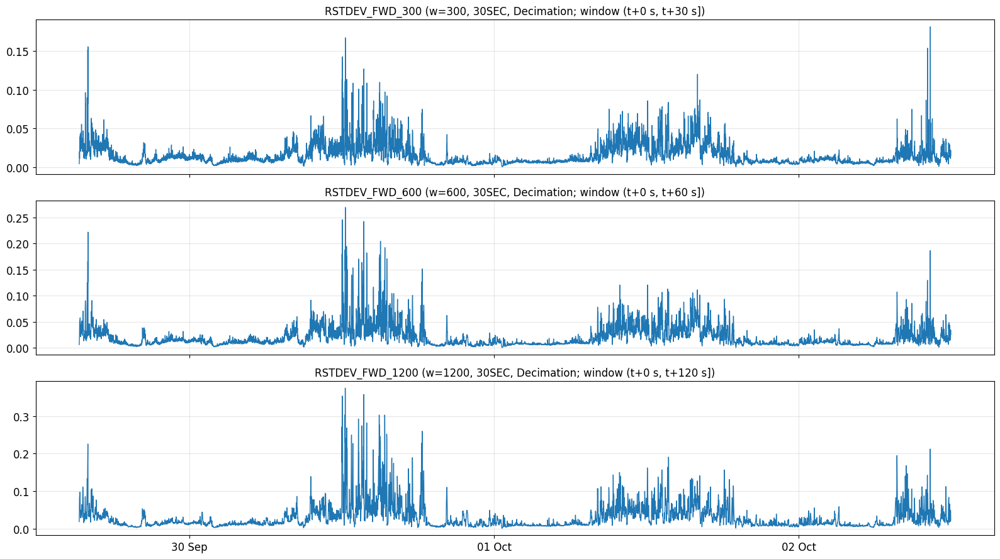

Saving figure RSTDEV_DSAVG_30SEC


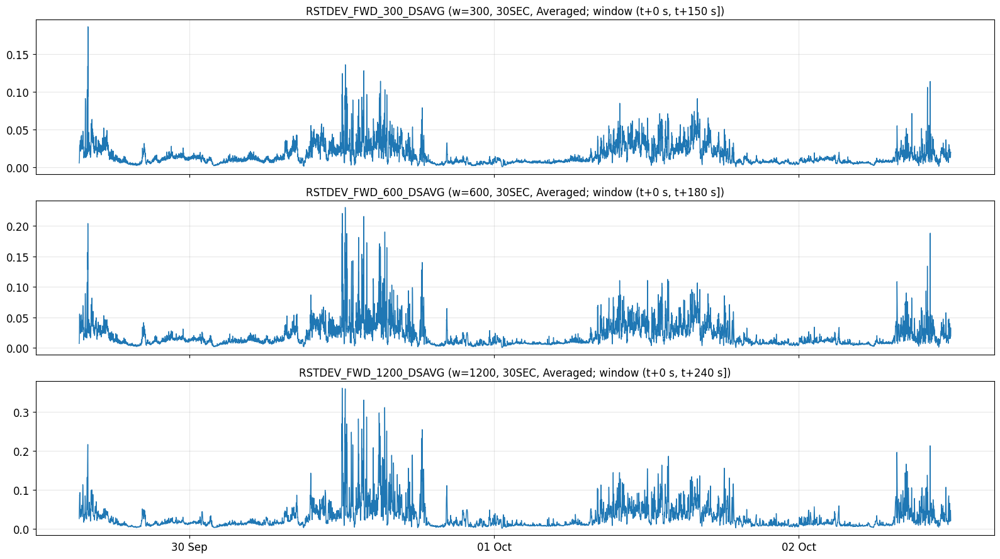

Saving figure RSTDEV_DSMAX_30SEC


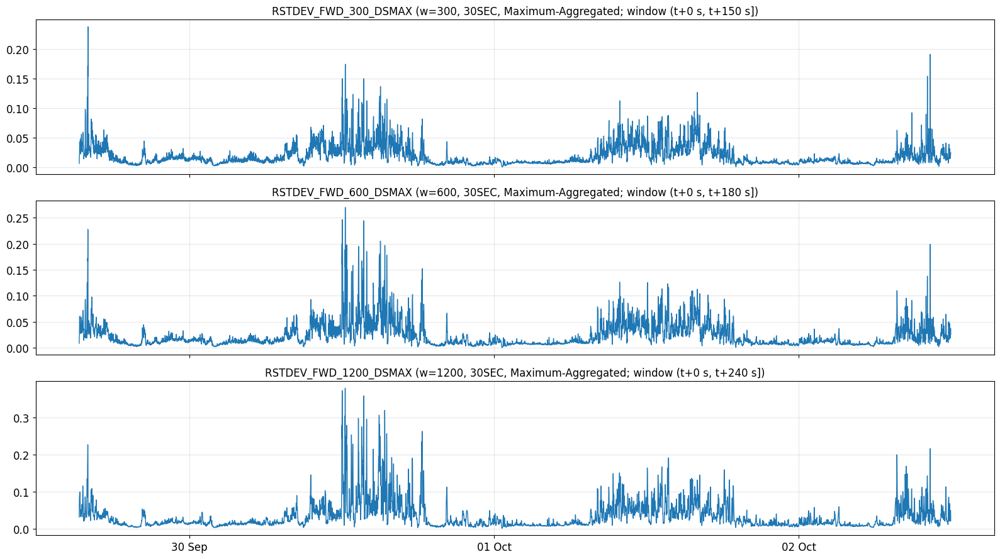

Saving figure RSTDEV_SAVGOL_30SEC


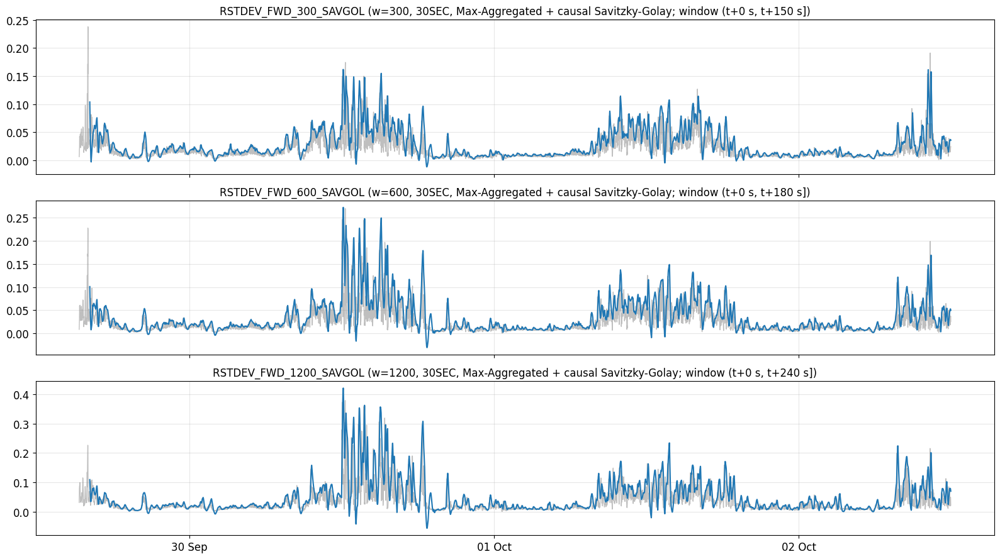

Saving figure REXD_DEC_30SEC


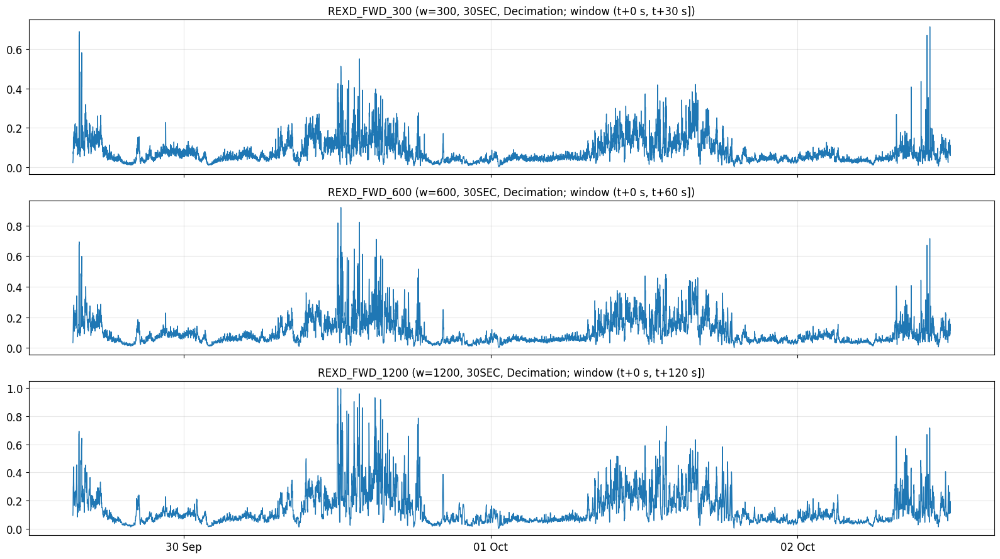

Saving figure REXD_DSAVG_30SEC


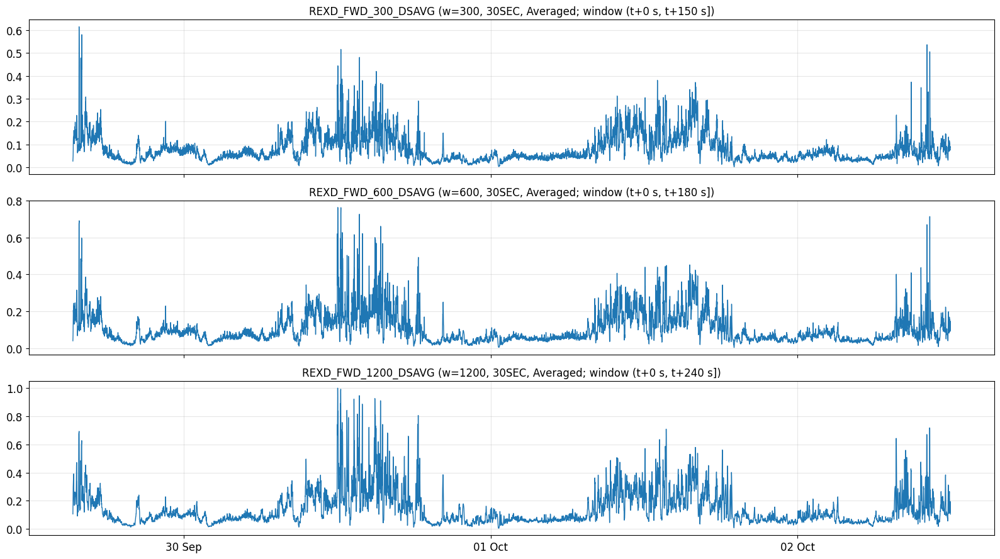

Saving figure REXD_DSMAX_30SEC


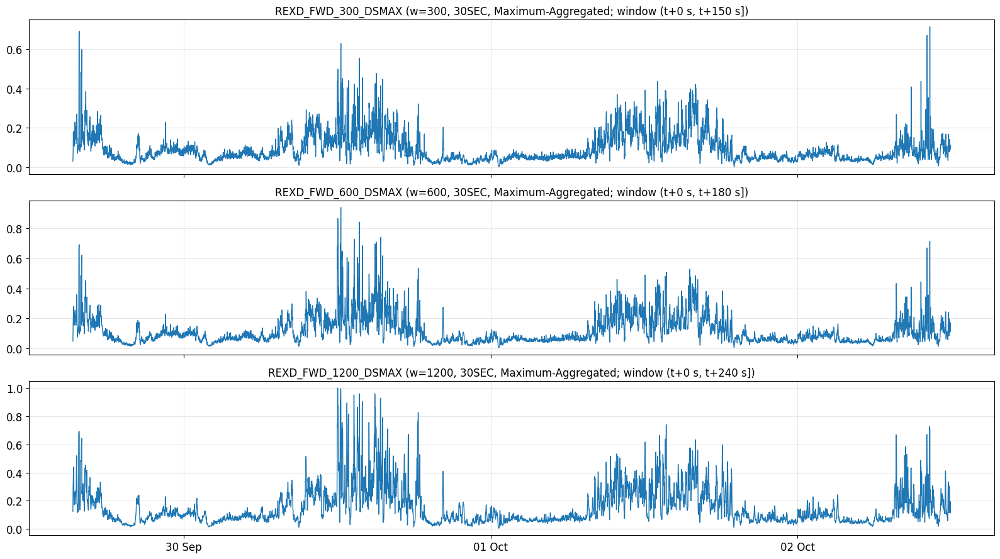

Saving figure REXD_SAVGOL_30SEC


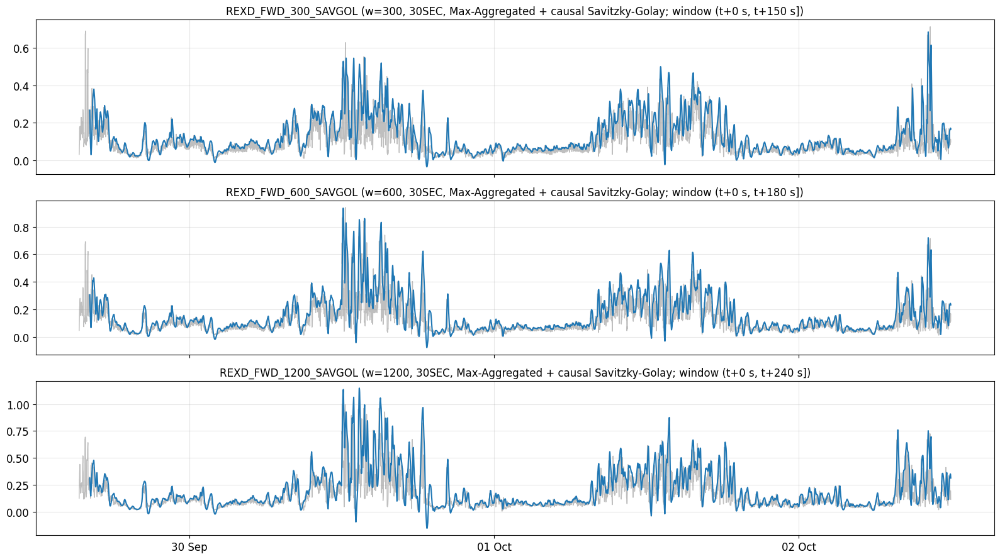

In [13]:
VARIANT_LABELS = {"DEC": "Decimation", "DSAVG": "Averaged", "DSMAX": "Maximum-Aggregated", "SAVGOL": "Max-Aggregated + causal Savitzky-Golay"}
sf_label = FEATURE_PLOT_SAMPLING
for metric in ("RSTDEV", "REXD"):
    for variant, vlabel in VARIANT_LABELS.items():
        cols = [t for t in PRIMARY_TARGETS if TARGET_META[t]["metric"] == metric and TARGET_META[t]["variant"] == variant]
        fig, axes = plt.subplots(nrows=len(cols), ncols=1, sharex=True, figsize=(16, 9))
        for ax, col in zip(axes, cols):
            if variant == "SAVGOL":
                ax.plot(plot_df["dt"], plot_df[col.replace("_SAVGOL", "_DSMAX")], color="gray", alpha=0.5, linewidth=1.0)
            ax.plot(plot_df["dt"], plot_df[col], linewidth=1.5 if variant == "SAVGOL" else 1.0)
            ax.set_title(f"{col} (w={TARGET_META[col]['window_samples']}, {sf_label}, {vlabel}; window (t+{TARGET_META[col]['window_start_offset_s']:.0f} s, t+{TARGET_META[col]['window_end_offset_s']:.0f} s])")
            ax.grid(True, alpha=0.3)
        format_date_axis(axes[-1])
        save_fig(f"{metric}_{variant}_{sf_label}")
        plt.show()

Saving figure d_Fidelity_30SEC


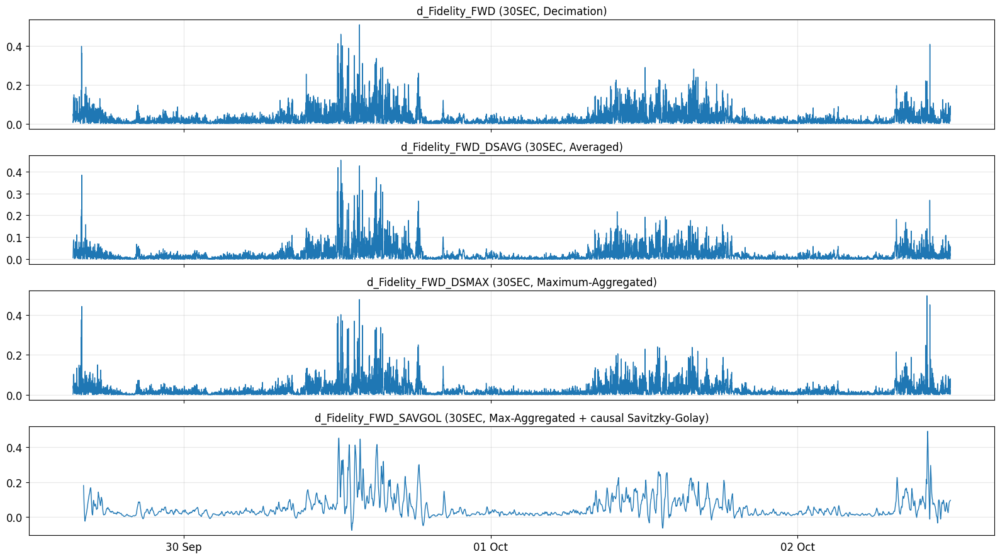

Saving figure d2_Fidelity_30SEC


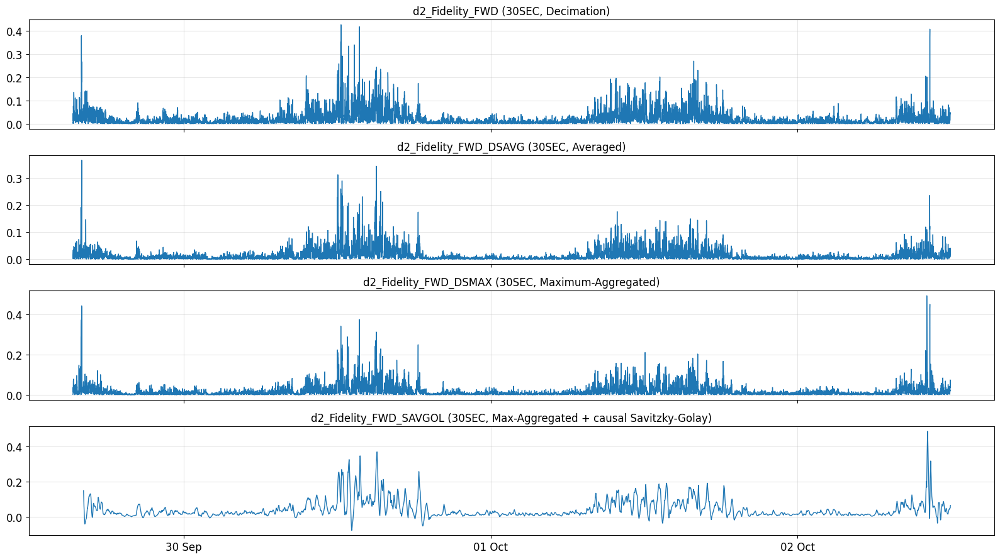

In [14]:
# derivative targets (GLM only)
for order, metric in ((1, "d_Fidelity"), (2, "d2_Fidelity")):
    cols = [t for t in PRIMARY_TARGETS if TARGET_META[t]["metric"] == metric]
    fig, axes = plt.subplots(nrows=len(cols), ncols=1, sharex=True, figsize=(16, 9))
    for ax, col in zip(axes, cols):
        ax.plot(plot_df["dt"], plot_df[col], linewidth=1.0)
        ax.set_title(f"{col} ({sf_label}, {VARIANT_LABELS[TARGET_META[col]['variant']]})")
        ax.grid(True, alpha=0.3)
    format_date_axis(axes[-1])
    save_fig(f"{metric}_{sf_label}")
    plt.show()

## 8. Feature distributions and target/feature relationships (non-test rows ONLY)

Saving figure feature_histograms_30SEC


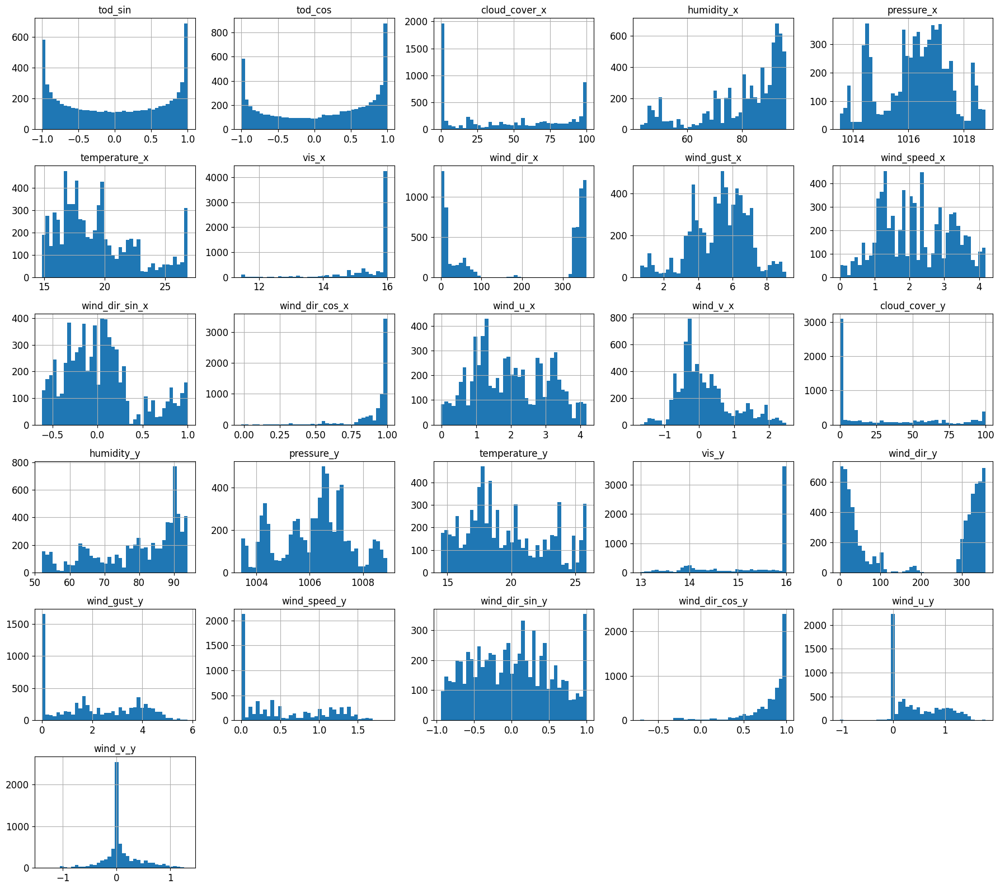

In [15]:
explore_df = non_test_rows(plot_df, FEATURE_PLOT_SAMPLING)
explore_df[FEATURES].hist(bins=40, figsize=(18, 16))
save_fig(f"feature_histograms_{FEATURE_PLOT_SAMPLING}")
plt.show()

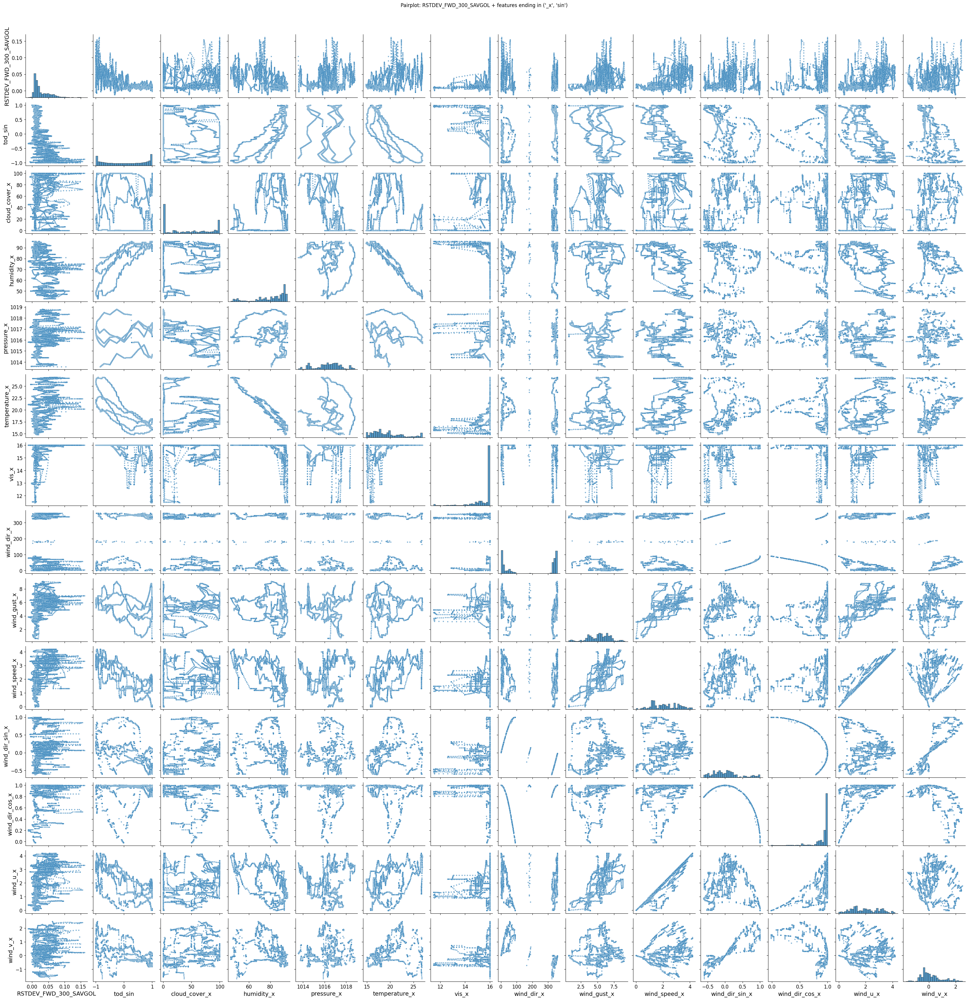

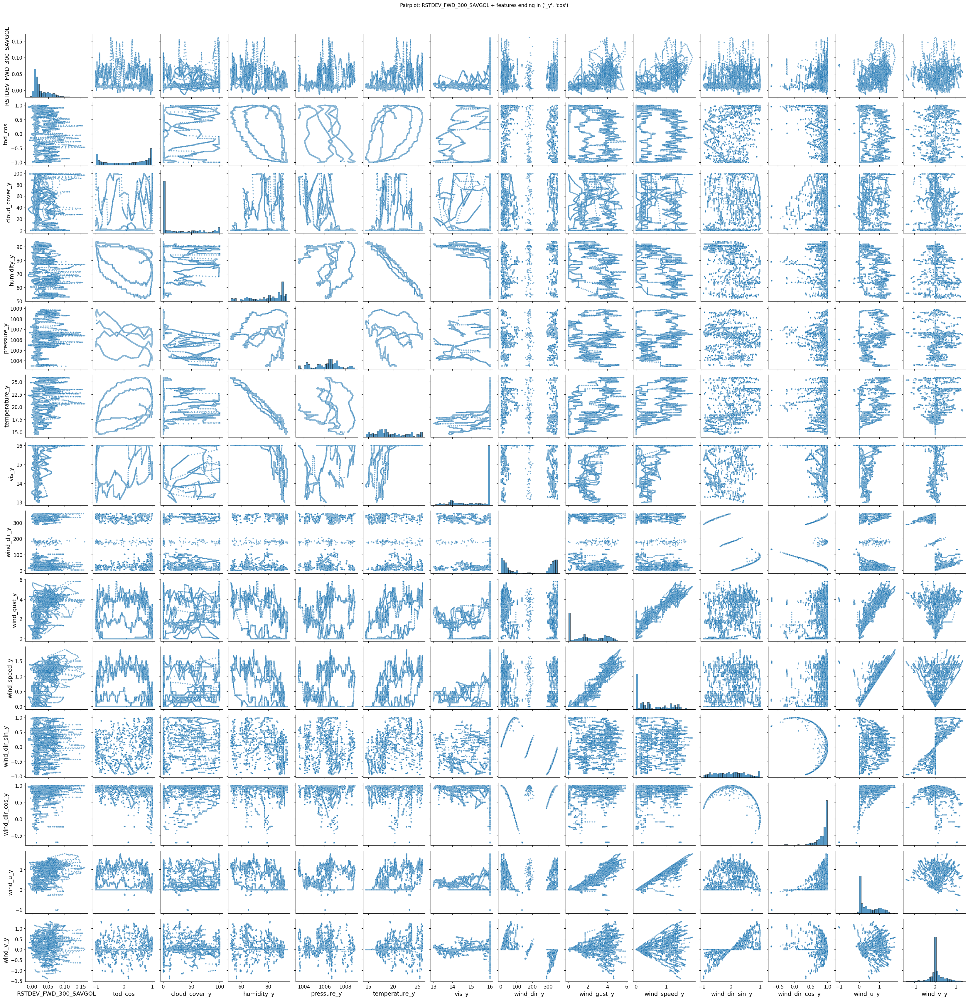

In [16]:
for suffixes in (("_x", "sin"), ("_y", "cos")):
    cols = [PAIRPLOT_TARGET] + [c for c in FEATURES if c.endswith(suffixes)]
    g = sns.pairplot(explore_df[cols].dropna(), diag_kind="hist", height=2.4, plot_kws=dict(s=10, alpha=0.6), diag_kws=dict(bins=30))
    g.fig.suptitle(f"Pairplot: {PAIRPLOT_TARGET} + features ending in {suffixes}", y=1.02)
    plt.show()

Saving figure scatter_RSTDEV_FWD_300_SAVGOL_vs_features


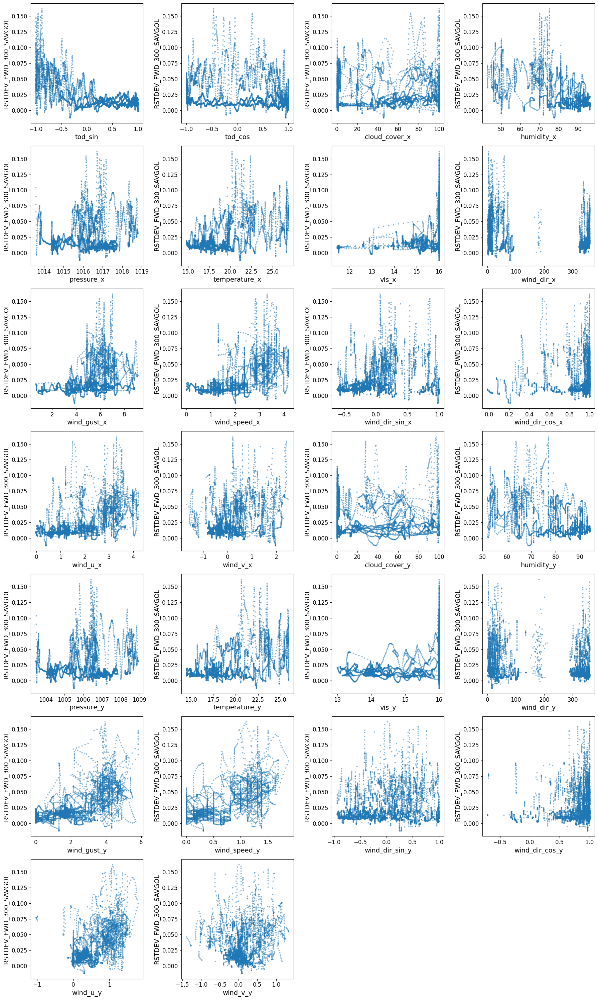

In [17]:
fig, axes = plt.subplots(int(np.ceil(len(FEATURES) / 4)), 4, figsize=(18, 30))

for ax, c in zip(axes.ravel(), FEATURES):
    ax.scatter(explore_df[c], explore_df[PAIRPLOT_TARGET], s=4, alpha=0.4)
    ax.set_xlabel(c)
    ax.set_ylabel(PAIRPLOT_TARGET)
    
for ax in axes.ravel()[len(FEATURES):]:
    ax.set_visible(False)
    
save_fig(f"scatter_{PAIRPLOT_TARGET}_vs_features")

plt.show()

## 9. Correlation screening (Section 3.3)

pearson correlation of each feature with each lead 0 target (including the derivative targets) plus the top degree 2 polynomial terms. Test rows are excluded.

In [18]:
linear_rows, poly_rows = [], []
for sampling, df in datasets.items():
    num = non_test_rows(df, sampling)
    poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
    for t in PRIMARY_TARGETS:
        sub = num[FEATURES + [t]].dropna()
        corr = sub[FEATURES].corrwith(sub[t])
        for feat, val in corr.items():
            linear_rows.append({"sampling": sampling, "target": t, "feature": feat, "r": val})
        poly_df = pd.DataFrame(poly.fit_transform(sub[FEATURES]), columns=poly.get_feature_names_out(FEATURES), index=sub.index)
        poly_df = poly_df.loc[:, poly_df.std() > 0]
        pc = poly_df.corrwith(sub[t])
        for feat, val in pc.loc[pc.abs().sort_values(ascending=False).head(POLY_TOP_N).index].items():
            poly_rows.append({"sampling": sampling, "target": t, "term": feat, "r": val})

lin_corr = pd.DataFrame(linear_rows)
lin_corr["abs_r"] = lin_corr["r"].abs()
lin_corr = lin_corr.sort_values(["sampling", "target", "abs_r"], ascending=[True, True, False])
poly_corr = pd.DataFrame(poly_rows)
lin_corr.to_csv(RESULTS_DIR / "lin_corr.csv", index=False)
poly_corr.to_csv(RESULTS_DIR / "poly_corr.csv", index=False)
lin_corr.groupby(["sampling", "target"]).head(5)

,sampling,target,feature,r,abs_r
1040,1MIN,REXD_FWD_1200,tod_sin,-0.622257,0.622257
1061,1MIN,REXD_FWD_1200,wind_speed_y,0.607428,0.607428
1060,1MIN,REXD_FWD_1200,wind_gust_y,0.578770,0.578770
1064,1MIN,REXD_FWD_1200,wind_u_y,0.567145,0.567145
1049,1MIN,REXD_FWD_1200,wind_speed_x,0.528204,0.528204
...,...,...,...,...,...
702,30SEC,d_Fidelity_FWD_SAVGOL,tod_sin,-0.567215,0.567215
723,30SEC,d_Fidelity_FWD_SAVGOL,wind_speed_y,0.541826,0.541826
722,30SEC,d_Fidelity_FWD_SAVGOL,wind_gust_y,0.516295,0.516295
726,30SEC,d_Fidelity_FWD_SAVGOL,wind_u_y,0.490263,0.490263
